# 04 · Exploratory Data Analysis

| | |
|---|---|
| **Question** | What separates borrowers who default from those who repay, and does that relationship hold over time? |
| **Inputs** | Cleaned splits from notebook 03 (train 2012 to 2014, validation 2015) |
| **Outputs** | Ranked list of risk drivers, redundancy map, stability check, the benchmark to beat |
| **Skills shown** | Risk curves, effect sizes over p-values, interaction analysis, correlation and redundancy, temporal stability |

All exploration uses the **training set only**. The 2015 validation set appears only in the stability check, and the 2016 test set is not opened at all. Looking at the test set during exploration would quietly bias every later decision.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

from meridian import config, viz
from meridian.data import TARGET
from meridian.features.cleaning import FEATURES_CATEGORICAL, FEATURES_NUMERIC

viz.set_style()
FEATURES_DIR = config.DATA_DIR / "features"
train = pd.read_parquet(FEATURES_DIR / "pd_train.parquet")
valid = pd.read_parquet(FEATURES_DIR / "pd_validation.parquet")
for d in (train, valid):
    d[TARGET] = d[TARGET].astype(float)
y = train[TARGET].astype(int)
BASE = y.mean()
print(f"Training loans: {len(train):,}   bad loans: {y.sum():,}   bad rate: {BASE:.2%}")

Training loans: 423,810   bad loans: 37,971   bad rate: 8.96%


## 1. The target

About 1 in 11 training loans defaulted within 24 months. The classes are imbalanced but not extremely so. With 38,000 defaults there is plenty of signal, so no resampling (such as SMOTE) is needed. Resampling would also distort the probabilities, and a PD model must output *calibrated* probabilities because they feed directly into Expected Loss in dollars.

## 2. Risk curves for the main numeric drivers

Each panel splits borrowers into ten equal-sized groups (deciles) by one variable and shows the bad rate in each group. The grey line is the overall bad rate. A steep, steady slope means a strong and well-behaved driver.

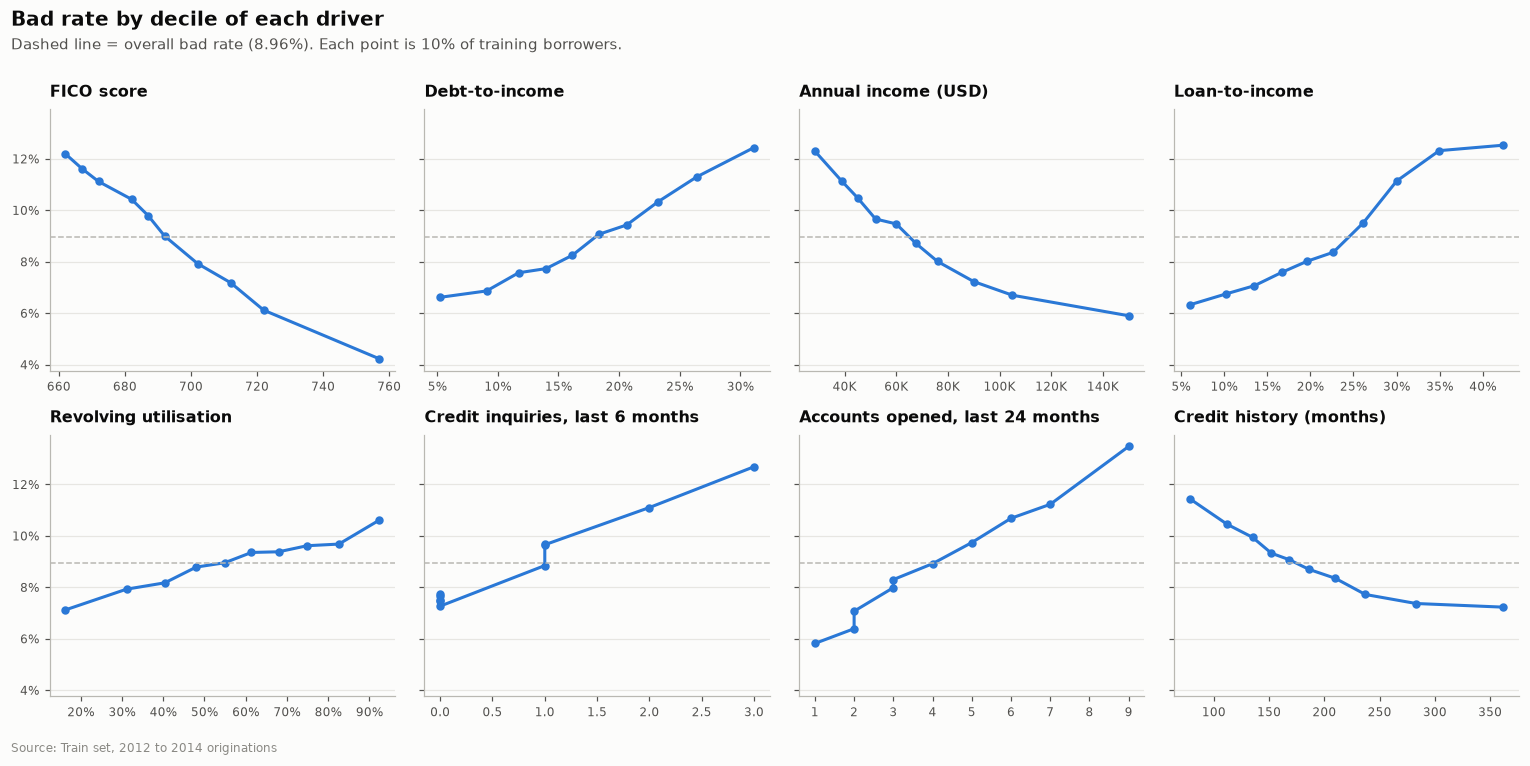

In [2]:
def risk_curve(df, col, q=10):
    s = df[col].astype(float)
    bins = pd.qcut(s.rank(method="first"), q, labels=False)
    g = df.assign(_b=bins).groupby("_b").agg(x=(col, "median"), bad=(TARGET, lambda v: v.astype(float).mean()), n=(TARGET, "size"))
    return g

panels = [("fico_score", "FICO score"), ("debt_to_income", "Debt-to-income"), ("annual_income", "Annual income (USD)"),
          ("loan_to_income", "Loan-to-income"), ("revolving_utilization", "Revolving utilisation"),
          ("inquiries_6m", "Credit inquiries, last 6 months"), ("accounts_opened_24m", "Accounts opened, last 24 months"),
          ("credit_history_months", "Credit history (months)")]

fig, axes = plt.subplots(2, 4, figsize=(14, 6.4), sharey=True)
for ax, (col, label) in zip(axes.flat, panels):
    g = risk_curve(train, col)
    ax.plot(g.x, g.bad, color=viz.BLUE, marker="o", ms=4.5)
    ax.axhline(BASE, color=viz.NEUTRAL, lw=1, ls="--")
    ax.set_title(label, fontsize=10.5, pad=8)
    viz.pct(ax)
    ax.tick_params(labelsize=8)
    if col == "annual_income":
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1e3:,.0f}K"))
    if col in ("debt_to_income", "loan_to_income", "revolving_utilization"):
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.suptitle("Bad rate by decile of each driver", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.03)
fig.text(0.01, 0.975, "Dashed line = overall bad rate (8.96%). Each point is 10% of training borrowers.",
         fontsize=9.5, color=viz.INK_2, ha="left")
fig.tight_layout()
viz.source(fig, "Train set, 2012 to 2014 originations", y=-0.01)
plt.show()

In [3]:
curves = {label: risk_curve(train, col) for col, label in panels}
pd.DataFrame({label: {"bad_rate_lowest_decile": g.bad.iloc[0], "bad_rate_highest_decile": g.bad.iloc[-1],
                      "ratio_high_to_low": g.bad.iloc[-1] / g.bad.iloc[0]} for label, g in curves.items()}).T \
  .style.format({"bad_rate_lowest_decile": "{:.2%}", "bad_rate_highest_decile": "{:.2%}", "ratio_high_to_low": "{:.2f}x"})

,bad_rate_lowest_decile,bad_rate_highest_decile,ratio_high_to_low
FICO score,12.19%,4.23%,0.35x
Debt-to-income,6.62%,12.44%,1.88x
Annual income (USD),12.30%,5.90%,0.48x
Loan-to-income,6.32%,12.53%,1.98x
Revolving utilisation,7.12%,10.61%,1.49x
"Credit inquiries, last 6 months",7.68%,12.68%,1.65x
"Accounts opened, last 24 months",5.82%,13.48%,2.32x
Credit history (months),11.45%,7.23%,0.63x


**What the curves say:**

- **FICO score** is the strongest single driver and slopes cleanly downward: the lowest-FICO decile defaults about three times as often as the highest (12.2% versus 4.2%).
- **Debt-to-income, loan-to-income, inquiries and new accounts** all slope upward. Each describes a borrower who is stretching: more debt per dollar earned, more recent credit-seeking. Accounts opened in the last 24 months has the widest spread of all: 5.8% in the lowest decile versus 13.4% in the highest.
- **Income and credit history length** protect: higher income and older credit files default less.
- **Revolving utilisation** rises with risk, but the curve flattens at the top. Several relationships are **non-linear**, which is exactly what Weight of Evidence binning (notebook 05) and gradient boosting (notebook 07) handle well.

## 3. Categorical drivers

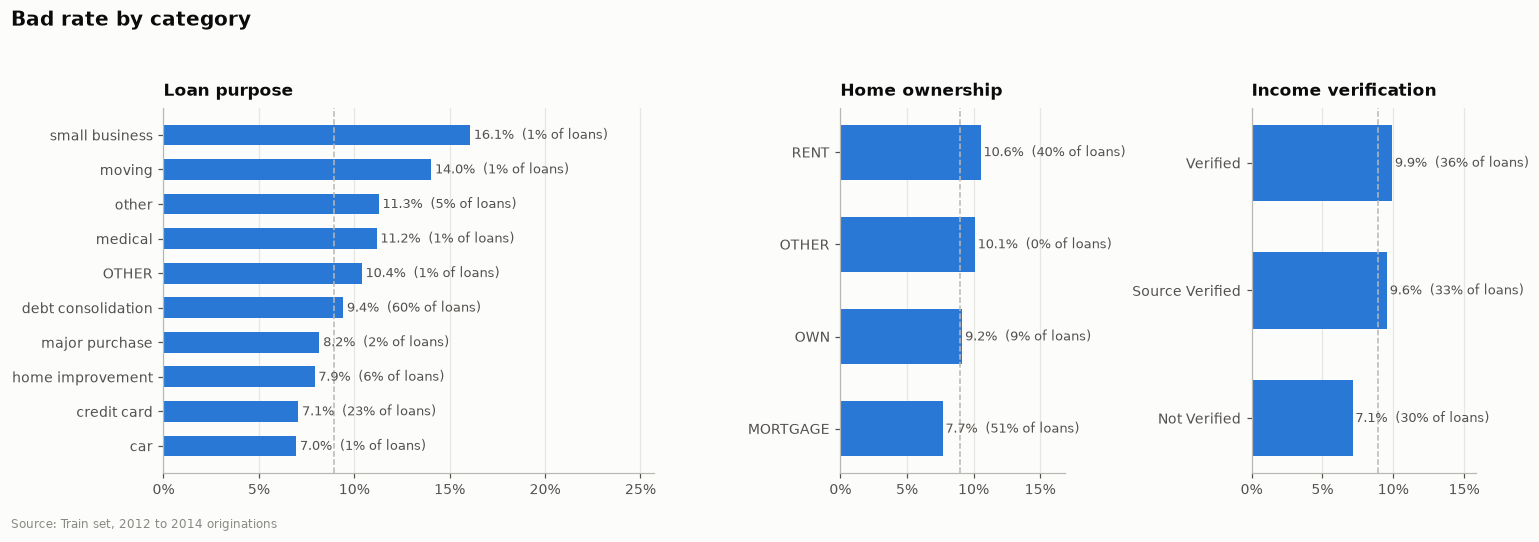

In [4]:
def cat_table(col):
    g = train.groupby(col, observed=True)[TARGET].agg(loans="size", bad_rate=lambda v: v.astype(float).mean())
    g["share"] = g.loans / g.loans.sum()
    return g.sort_values("bad_rate")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), gridspec_kw={"width_ratios": [2.4, 1.1, 1.1]})
for ax, col, title in [(axes[0], "loan_purpose", "Loan purpose"), (axes[1], "home_ownership", "Home ownership"),
                       (axes[2], "income_verification", "Income verification")]:
    g = cat_table(col)
    ax.barh(g.index.astype(str).str.replace("_", " "), g.bad_rate, color=viz.BLUE, height=0.6)
    ax.axvline(BASE, color=viz.NEUTRAL, lw=1, ls="--")
    for i, (v, s) in enumerate(zip(g.bad_rate, g.share)):
        ax.text(v + 0.002, i, f"{v:.1%}  ({s:.0%} of loans)", va="center", fontsize=8.5, color=viz.INK_2)
    ax.set_xlim(0, g.bad_rate.max() * 1.6)
    viz.pct(ax, axis="x")
    ax.grid(axis="x", color=viz.GRID)
    ax.grid(axis="y", visible=False)
    ax.set_title(title, fontsize=11, pad=8)
fig.suptitle("Bad rate by category", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.04)
fig.tight_layout()
viz.source(fig, "Train set, 2012 to 2014 originations", y=-0.01)
plt.show()

In [5]:
term = train.groupby("term_months")[TARGET].agg(loans="size", bad_rate=lambda v: v.astype(float).mean())
term["share"] = term.loans / term.loans.sum()
term.style.format({"loans": "{:,.0f}", "bad_rate": "{:.2%}", "share": "{:.1%}"})

,loans,bad_rate,share
term_months,,,
36,"306,462",7.95%,72.3%
60,"117,348",11.60%,27.7%


**What the categories say:**

- **Term:** 60-month loans default at 11.6% versus 8.0% for 36-month loans, about 1.5 times as often. Longer terms go to larger loans and to borrowers who need a lower monthly payment to qualify.
- **Purpose matters:** small-business and moving loans are the riskiest. Credit card refinancing and car loans are the safest.
- **Renters default more than homeowners** with a mortgage.
- **The verification paradox:** borrowers whose income was *verified* default **more** than those whose income was not. Verification does not cause default. Lending Club chose to verify the applications it already considered risky. This is a selection effect, and a good example of why correlation in credit data must be interpreted with knowledge of the underwriting process.

## 4. Interaction: FICO and term together

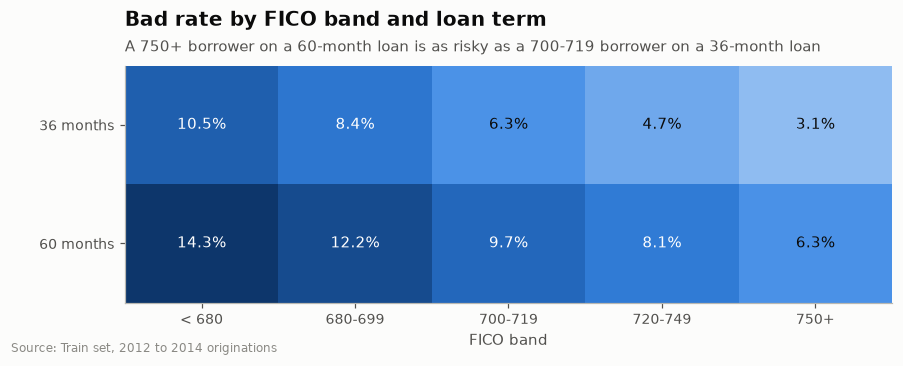

In [6]:
fico_band = pd.cut(train.fico_score, [0, 680, 700, 720, 750, 900], labels=["< 680", "680-699", "700-719", "720-749", "750+"])
inter = train.assign(fico_band=fico_band).pivot_table(index="term_months", columns="fico_band", values=TARGET,
                                                      aggfunc=lambda v: v.astype(float).mean(), observed=True)
fig, ax = plt.subplots(figsize=(9, 2.8))
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("seq", viz.SEQ_BLUE)
ax.imshow(inter.values, cmap=cmap, aspect="auto", vmin=0, vmax=inter.values.max())
ax.set_xticks(range(inter.shape[1]), inter.columns)
ax.set_yticks(range(inter.shape[0]), [f"{t} months" for t in inter.index])
ax.grid(False)
for i in range(inter.shape[0]):
    for j in range(inter.shape[1]):
        v = inter.values[i, j]
        ax.text(j, i, f"{v:.1%}", ha="center", va="center", fontsize=10,
                color="white" if v > inter.values.max() * 0.55 else viz.INK)
ax.set_xlabel("FICO band")
ax.set_title("Bad rate by FICO band and loan term")
viz.subtitle(ax, "A 750+ borrower on a 60-month loan is as risky as a 700-719 borrower on a 36-month loan")
viz.source(fig, "Train set, 2012 to 2014 originations")
plt.show()

**What it means:** term and FICO add up. Neither cancels the other. A lender looking only at FICO would misprice long-term loans across every band. The model needs both, and the challenger model in notebook 07 can learn such interactions automatically.

## 5. Ranking every driver by predictive power

With 424,000 loans, almost every variable is "statistically significant" at p < 0.001, so p-values cannot rank drivers. **Effect size** is what matters. Here, effect size is measured by the univariate AUC: how well the variable alone ranks bad borrowers above good ones (0.5 = no signal).

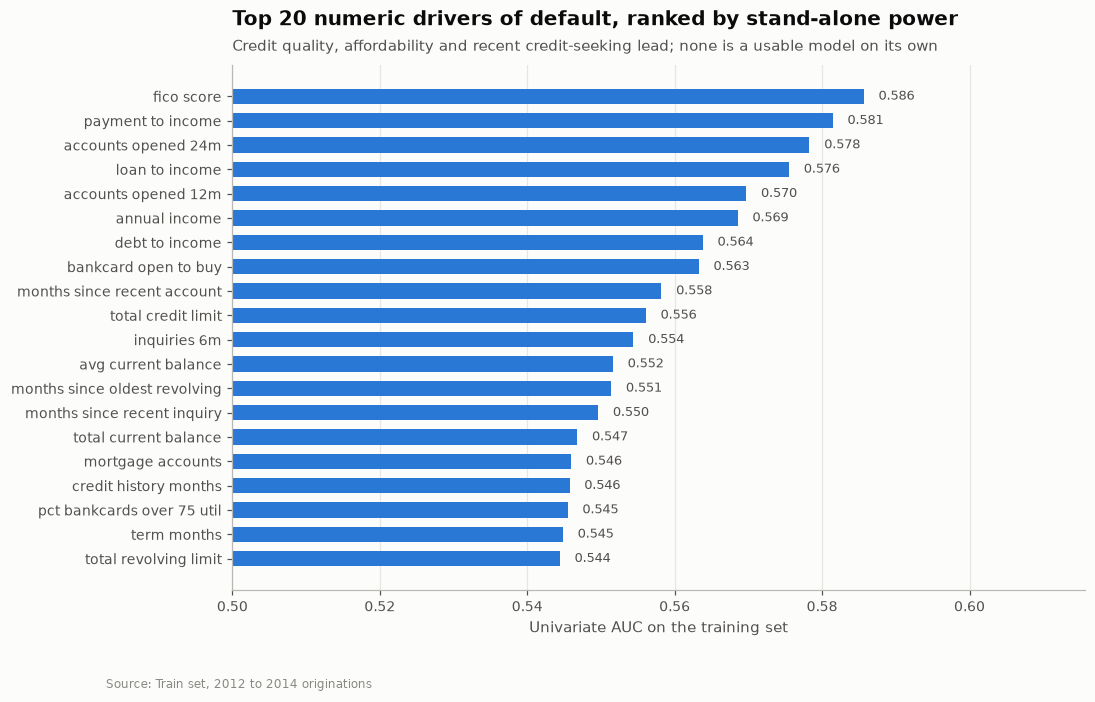

In [7]:
def uni_auc(df, col):
    s = df[col].astype(float)
    s = s.fillna(s.median() if s.notna().any() else 0)
    if s.nunique() < 2:
        return np.nan
    a = roc_auc_score(df[TARGET].astype(int), s)
    return max(a, 1 - a)

numeric = [c for c in FEATURES_NUMERIC if c != "is_joint_application"]
auc_rank = pd.DataFrame({"train_auc": {c: uni_auc(train, c) for c in numeric},
                         "validation_auc": {c: uni_auc(valid, c) for c in numeric}}).dropna()
auc_rank["change"] = auc_rank.validation_auc - auc_rank.train_auc
auc_rank = auc_rank.sort_values("train_auc", ascending=False)

top = auc_rank.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6.2))
ax.barh(top.index.str.replace("_", " "), top.train_auc - 0.5, left=0.5, color=viz.BLUE, height=0.62)
for i, v in enumerate(top.train_auc):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8.5, color=viz.INK_2)
ax.set_xlim(0.5, top.train_auc.max() + 0.03)
ax.grid(axis="x", color=viz.GRID)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Univariate AUC on the training set")
ax.set_title("Top 20 numeric drivers of default, ranked by stand-alone power")
viz.subtitle(ax, "Credit quality, affordability and recent credit-seeking lead; none is a usable model on its own")
viz.source(fig, "Train set, 2012 to 2014 originations")
plt.show()

**What it means:** the best single variables reach an AUC of only about 0.58 to 0.60. Default is not driven by one factor. It is the combination of term, credit quality, leverage and recent credit behaviour. That is why a multivariate model is needed, and why the scorecard in notebook 06 combines around 15 to 20 variables.

## 6. Redundancy: which variables say the same thing?

Highly correlated variables add little new information and make coefficients unstable in a regression. The map below shows Spearman rank correlations among the top drivers.

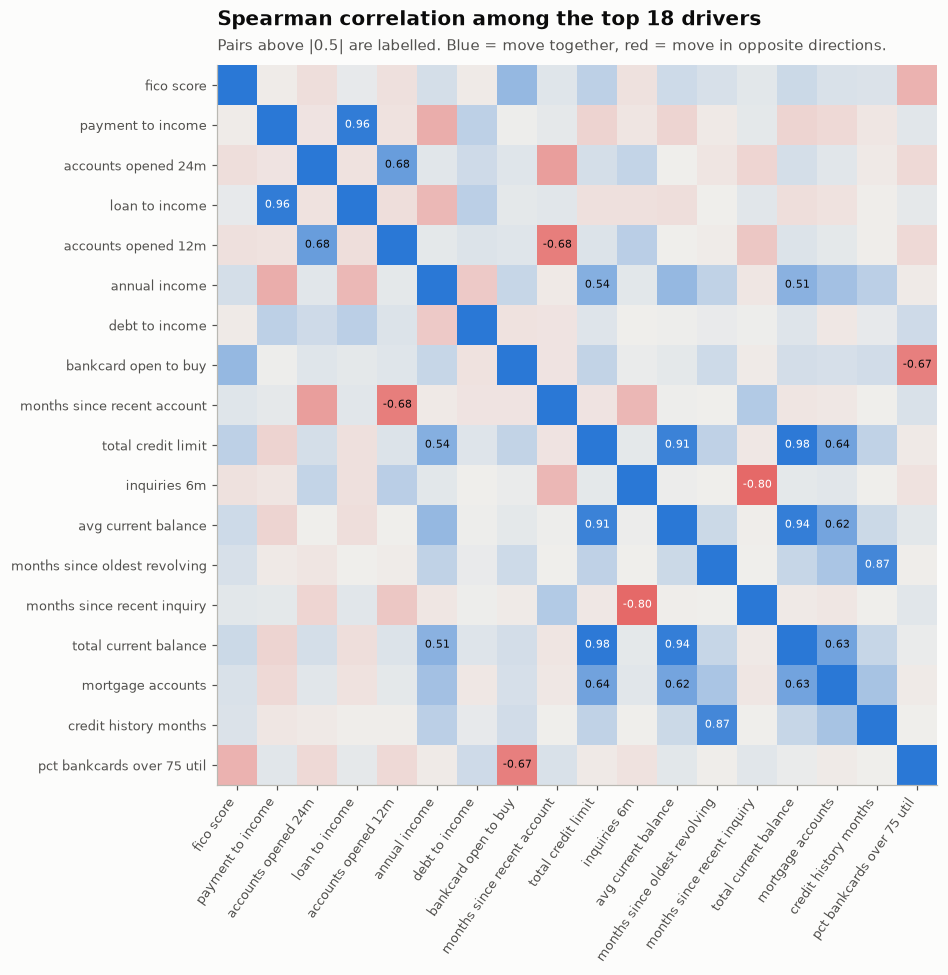

level_0,level_1,spearman,abs_corr
total_credit_limit,total_current_balance,+0.98,0.98
payment_to_income,loan_to_income,+0.96,0.96
avg_current_balance,total_current_balance,+0.94,0.94
total_credit_limit,avg_current_balance,+0.91,0.91
months_since_oldest_revolving,credit_history_months,+0.87,0.87
inquiries_6m,months_since_recent_inquiry,-0.80,0.80
accounts_opened_24m,accounts_opened_12m,+0.68,0.68
accounts_opened_12m,months_since_recent_account,-0.68,0.68


In [8]:
top_cols = auc_rank.head(18).index.tolist()
corr = train[top_cols].astype(float).corr(method="spearman")

fig, ax = plt.subplots(figsize=(10.5, 8.5))
div = plt.matplotlib.colors.LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])
ax.imshow(corr.values, cmap=div, vmin=-1, vmax=1)
labels = [c.replace("_", " ") for c in top_cols]
ax.set_xticks(range(len(labels)), labels, rotation=55, ha="right", fontsize=8.5)
ax.set_yticks(range(len(labels)), labels, fontsize=8.5)
ax.grid(False)
for i in range(len(labels)):
    for j in range(len(labels)):
        v = corr.values[i, j]
        if i != j and abs(v) >= 0.5:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 0.75 else viz.INK)
ax.set_title("Spearman correlation among the top 18 drivers")
viz.subtitle(ax, "Pairs above |0.5| are labelled. Blue = move together, red = move in opposite directions.")
plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack().rename("spearman").reset_index()
         .assign(abs_corr=lambda d: d.spearman.abs()).sort_values("abs_corr", ascending=False))
pairs.head(8).style.format({"spearman": "{:+.2f}", "abs_corr": "{:.2f}"}).hide(axis="index")

**What it means:** a few groups of variables measure the same underlying idea, for example the two utilisation measures, the different credit-limit totals, or loan amount and instalment. Notebook 05 keeps the strongest member of each highly correlated group (|rho| > 0.7) for the scorecard. The challenger model can tolerate redundancy, but the scorecard must stay interpretable and stable.

## 7. Stability over time

A driver that weakens over time is a liability in a model meant to run for years. The chart compares each variable's predictive power in 2012 to 2014 (train) with 2015 (validation).

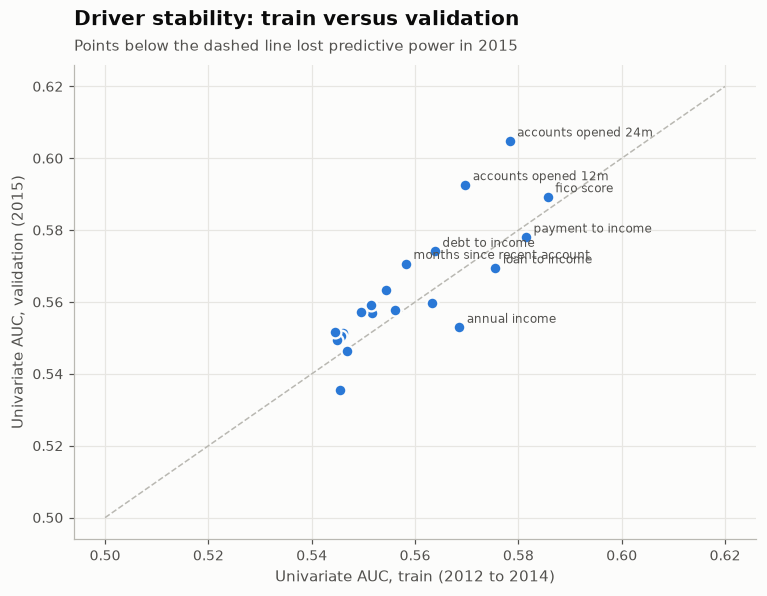

,train_auc,validation_auc,change
revolving_balance_to_income,+0.522,+0.501,-0.021
annual_income,+0.569,+0.553,-0.016
revolving_utilization,+0.533,+0.520,-0.013
bankcard_utilization,+0.543,+0.531,-0.013
total_accounts,+0.515,+0.503,-0.012
pct_bankcards_over_75_util,+0.545,+0.536,-0.010


In [9]:
st = auc_rank.head(20).copy()
fig, ax = plt.subplots(figsize=(8, 5.6))
ax.plot([0.5, 0.62], [0.5, 0.62], color=viz.NEUTRAL, lw=1, ls="--")
ax.scatter(st.train_auc, st.validation_auc, s=60, color=viz.BLUE, edgecolor=viz.SURFACE, linewidth=1.5, zorder=3)
for name, r in st.iterrows():
    if abs(r.change) > 0.01 or r.train_auc > 0.575:
        ax.annotate(name.replace("_", " "), (r.train_auc, r.validation_auc), xytext=(5, 3),
                    textcoords="offset points", fontsize=8, color=viz.INK_2)
ax.set_xlabel("Univariate AUC, train (2012 to 2014)")
ax.set_ylabel("Univariate AUC, validation (2015)")
ax.grid(axis="x", color=viz.GRID)
ax.set_title("Driver stability: train versus validation")
viz.subtitle(ax, "Points below the dashed line lost predictive power in 2015")
plt.show()
auc_rank.sort_values("change").head(6).style.format("{:+.3f}")

**What it means:** most drivers sit on or near the diagonal, so their meaning is stable from one year to the next. Two movements stand out:

- **Recent credit-seeking became more predictive.** Accounts opened in the last 12 and 24 months gained the most power in 2015. As lending loosened, borrowers who were opening many new lines were the ones who later failed.
- **Income and balance-based measures weakened** (annual income, revolving balance to income, utilisation). This is consistent with the debt-consolidation pattern from notebook 03: borrowers paid down their cards with the loan right before applying, which makes utilisation look better than the borrower really is.

The scorecard will monitor these drivers specifically (notebook 12).

## 8. The benchmark to beat

Lending Club assigned every loan a sub-grade (A1 to G5) with its own internal model. If Meridian's model cannot rank risk better than that, it has no reason to exist.

In [10]:
# Only the benchmark column and the target are read from test: no feature exploration happens on it.
test = pd.read_parquet(FEATURES_DIR / "pd_test_oot.parquet", columns=["benchmark_sub_grade", TARGET])
test[TARGET] = test[TARGET].astype(float)
grades = [f"{g}{i}" for g in "ABCDEFG" for i in range(1, 6)]
rank = {g: i for i, g in enumerate(grades)}

def grade_auc(df):
    r = df.benchmark_sub_grade.astype(str).map(rank)
    return roc_auc_score(df[TARGET].astype(int), r)

bench = pd.DataFrame({"AUC": {"Train 2012-14": grade_auc(train), "Validation 2015": grade_auc(valid),
                              "Test 2016": grade_auc(test)}})
bench["Gini"] = 2 * bench.AUC - 1
bench.style.format("{:.4f}")

,AUC,Gini
Train 2012-14,0.6630,0.3259
Validation 2015,0.6938,0.3875
Test 2016,0.6889,0.3777


Lending Club's sub-grade reaches a Gini of 0.33 on 2012 to 2014 loans and 0.38 to 0.39 on 2015 and 2016. This is the bar Meridian's scorecard has to clear on the 2016 test set, using **only** the information available at application time. The benchmark is strong because Lending Club's grade already combines many of the same bureau variables, and it was built by a team with years of data.

## 9. Key insights

| # | Insight | Consequence |
|---|---|---|
| 1 | FICO, affordability (payment and loan to income) and recent credit-seeking lead; term adds a 1.5x effect on top | All enter the model; interactions explored in the challenger |
| 2 | Leverage and recent credit-seeking (DTI, inquiries, new accounts) raise risk | Core of the "capacity" and "behaviour" sections of the scorecard |
| 3 | Several drivers are non-linear | WoE binning for the scorecard, gradient boosting for the challenger |
| 4 | Income verification shows a selection effect | Interpret with business context; keep as a feature, never as a causal claim |
| 5 | Groups of variables are redundant (|rho| > 0.7) | Keep the strongest of each group in the scorecard |
| 6 | New-account counts gained power in 2015; income and utilisation lost some | Flag for monitoring |
| 7 | Best single variable AUC is 0.59; Lending Club's grade reaches 0.69 on 2016 | A multivariate model is required, and the benchmark is demanding |

**Next:** notebook 05 turns these drivers into Weight of Evidence features and selects the final scorecard variables with Information Value.